In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Understanding the Data Set

In [77]:
df = pd.read_csv("/content/credit_default_classification.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  239 non-null    float64
 1   loan_amount_k        244 non-null    float64
 2   credit_score         233 non-null    float64
 3   home_owner           242 non-null    object 
 4   num_open_accounts    244 non-null    float64
 5   income_k             236 non-null    float64
 6   loan_purpose         233 non-null    object 
 7   defaulted            236 non-null    float64
 8   customer             246 non-null    object 
 9   months_since_delinq  246 non-null    float64
 10  credit_score_dup     233 non-null    float64
dtypes: float64(8), object(3)
memory usage: 22.2+ KB


In [78]:
df.head()

,age,loan_amount_k,credit_score,home_owner,num_open_accounts,income_k,loan_purpose,defaulted,customer,months_since_delinq,credit_score_dup
0,23.0,449.04,792.0,Ys,4.0,85.68,Debt cnsolidation,0.0,CR30000,3.0,792.0
1,62.0,122.05,637.0,Yes,9.0,41.04,Home improvemnt,0.0,CR30001,1.0,637.0
2,22.0,177.22,365.0,NaN,8.0,82.81,HOME IMPROVEMENT,0.0,CR30002,12.0,365.0
3,73.0,475.14,721.0,NO,7.0,142.80,Business,NaN,CR30003,6.0,721.0
4,49.0,289.66,839.0,NO,8.0,49.13,Home improvement,0.0,CR30004,0.0,839.0


In [79]:
df["age"].unique()

array([23., 62., 22., 73., 49., 66., 30., 47., 42., 77., 76., 45., 75.,
       37., 51., 60., 74., nan, 54., 65., 71., 80., 40., 64., 43., 31.,
       69., 53., 25., 57., 39., 33., 27., 50., 48., 38., 82., 21., 26.,
       79., 24., 68., 84., 41., 52., 70., 56., 19., 29., 55., 32., 67.,
       61., 78., 46., 81., 36., 35., 83., 59., 18., 28., 72., 58., 44.,
       20.])

In [80]:
df["age"] = df["age"].ffill()
df["loan_amount_k"] = df["loan_amount_k"].fillna(df["loan_amount_k"].mean().round(2))
df["credit_score"] = df["credit_score"].fillna(df["credit_score"].mean())


In [93]:
df["customer"].isnull().sum()

np.int64(0)

In [94]:
df["customer"].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [95]:
df["home_owner"] = df["home_owner"].replace(['Ys','es','YES','Ye'],'Yes')
df["home_owner"] = df["home_owner"].replace(['N','NO','o'],'No')
df["home_owner"] = df["home_owner"].bfill()

In [96]:
df["num_open_accounts"] = df["num_open_accounts"].fillna(df["num_open_accounts"].mode()[0])
df["income_k"] = df["income_k"].fillna(df["income_k"].mean())

In [97]:
df['loan_purpose'] = df['loan_purpose'].replace(['Debt cnsolidation', 'Dbt consolidation', 'Debt consolidation','Debt consolidton','Dbt consolidtion', 'Debt consolidtion', 'Debt consolidaton',], 'DEBT CONSOLIDATION')
df['loan_purpose'] = df['loan_purpose'].replace(['Home improvemnt','Home improvement', 'Hom improvement','Home imrovement','Home imrovement','Hme improvement','Hoe improvement','ome improvement','ome improvement','Home imprvement'],'HOME IMPROVEMENT')
df['loan_purpose'] = df['loan_purpose'].replace(['Business','Busines','Buiness','Busness','Bsiness','usiness','Busiess','Businss'],'BUSINESS')
df['loan_purpose'] = df['loan_purpose'].replace(['Cr','Car','ar'],'CAR')
df['loan_purpose'] = df['loan_purpose'].replace(['ducation','Education','Educatin', 'Eduction','Educaion','Educatio', 'Edcation','Eucation'],'EDUCATION')
df['loan_purpose'] = df['loan_purpose'].fillna(df['loan_purpose'].mode()[0])

In [98]:
df["defaulted"] = df["defaulted"].ffill()

In [99]:
df = df.drop(columns="customer")

In [100]:
df["customer"] = np.arange(1,258)

In [105]:
df["months_since_delinq"] = df["months_since_delinq"].fillna(df["months_since_delinq"].mode()[0])

In [ ]:
df = df.drop(columns="credit_score_dup")

In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  257 non-null    float64
 1   loan_amount_k        257 non-null    float64
 2   credit_score         257 non-null    float64
 3   home_owner           257 non-null    object 
 4   num_open_accounts    257 non-null    float64
 5   income_k             257 non-null    float64
 6   loan_purpose         257 non-null    object 
 7   defaulted            257 non-null    float64
 8   months_since_delinq  257 non-null    float64
 9   customer             257 non-null    int64  
dtypes: float64(7), int64(1), object(2)
memory usage: 20.2+ KB


In [104]:
df.to_csv("Preprocessed_Df.csv")

Univariate

/tmp/ipykernel_2890/3865871923.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df['income_k'],ax=ax[0][1],palette='Set1')
/tmp/ipykernel_2890/3865871923.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['home_owner'],ax=ax[1][1],palette='Set2')


Text(0, 0.5, 'Count')

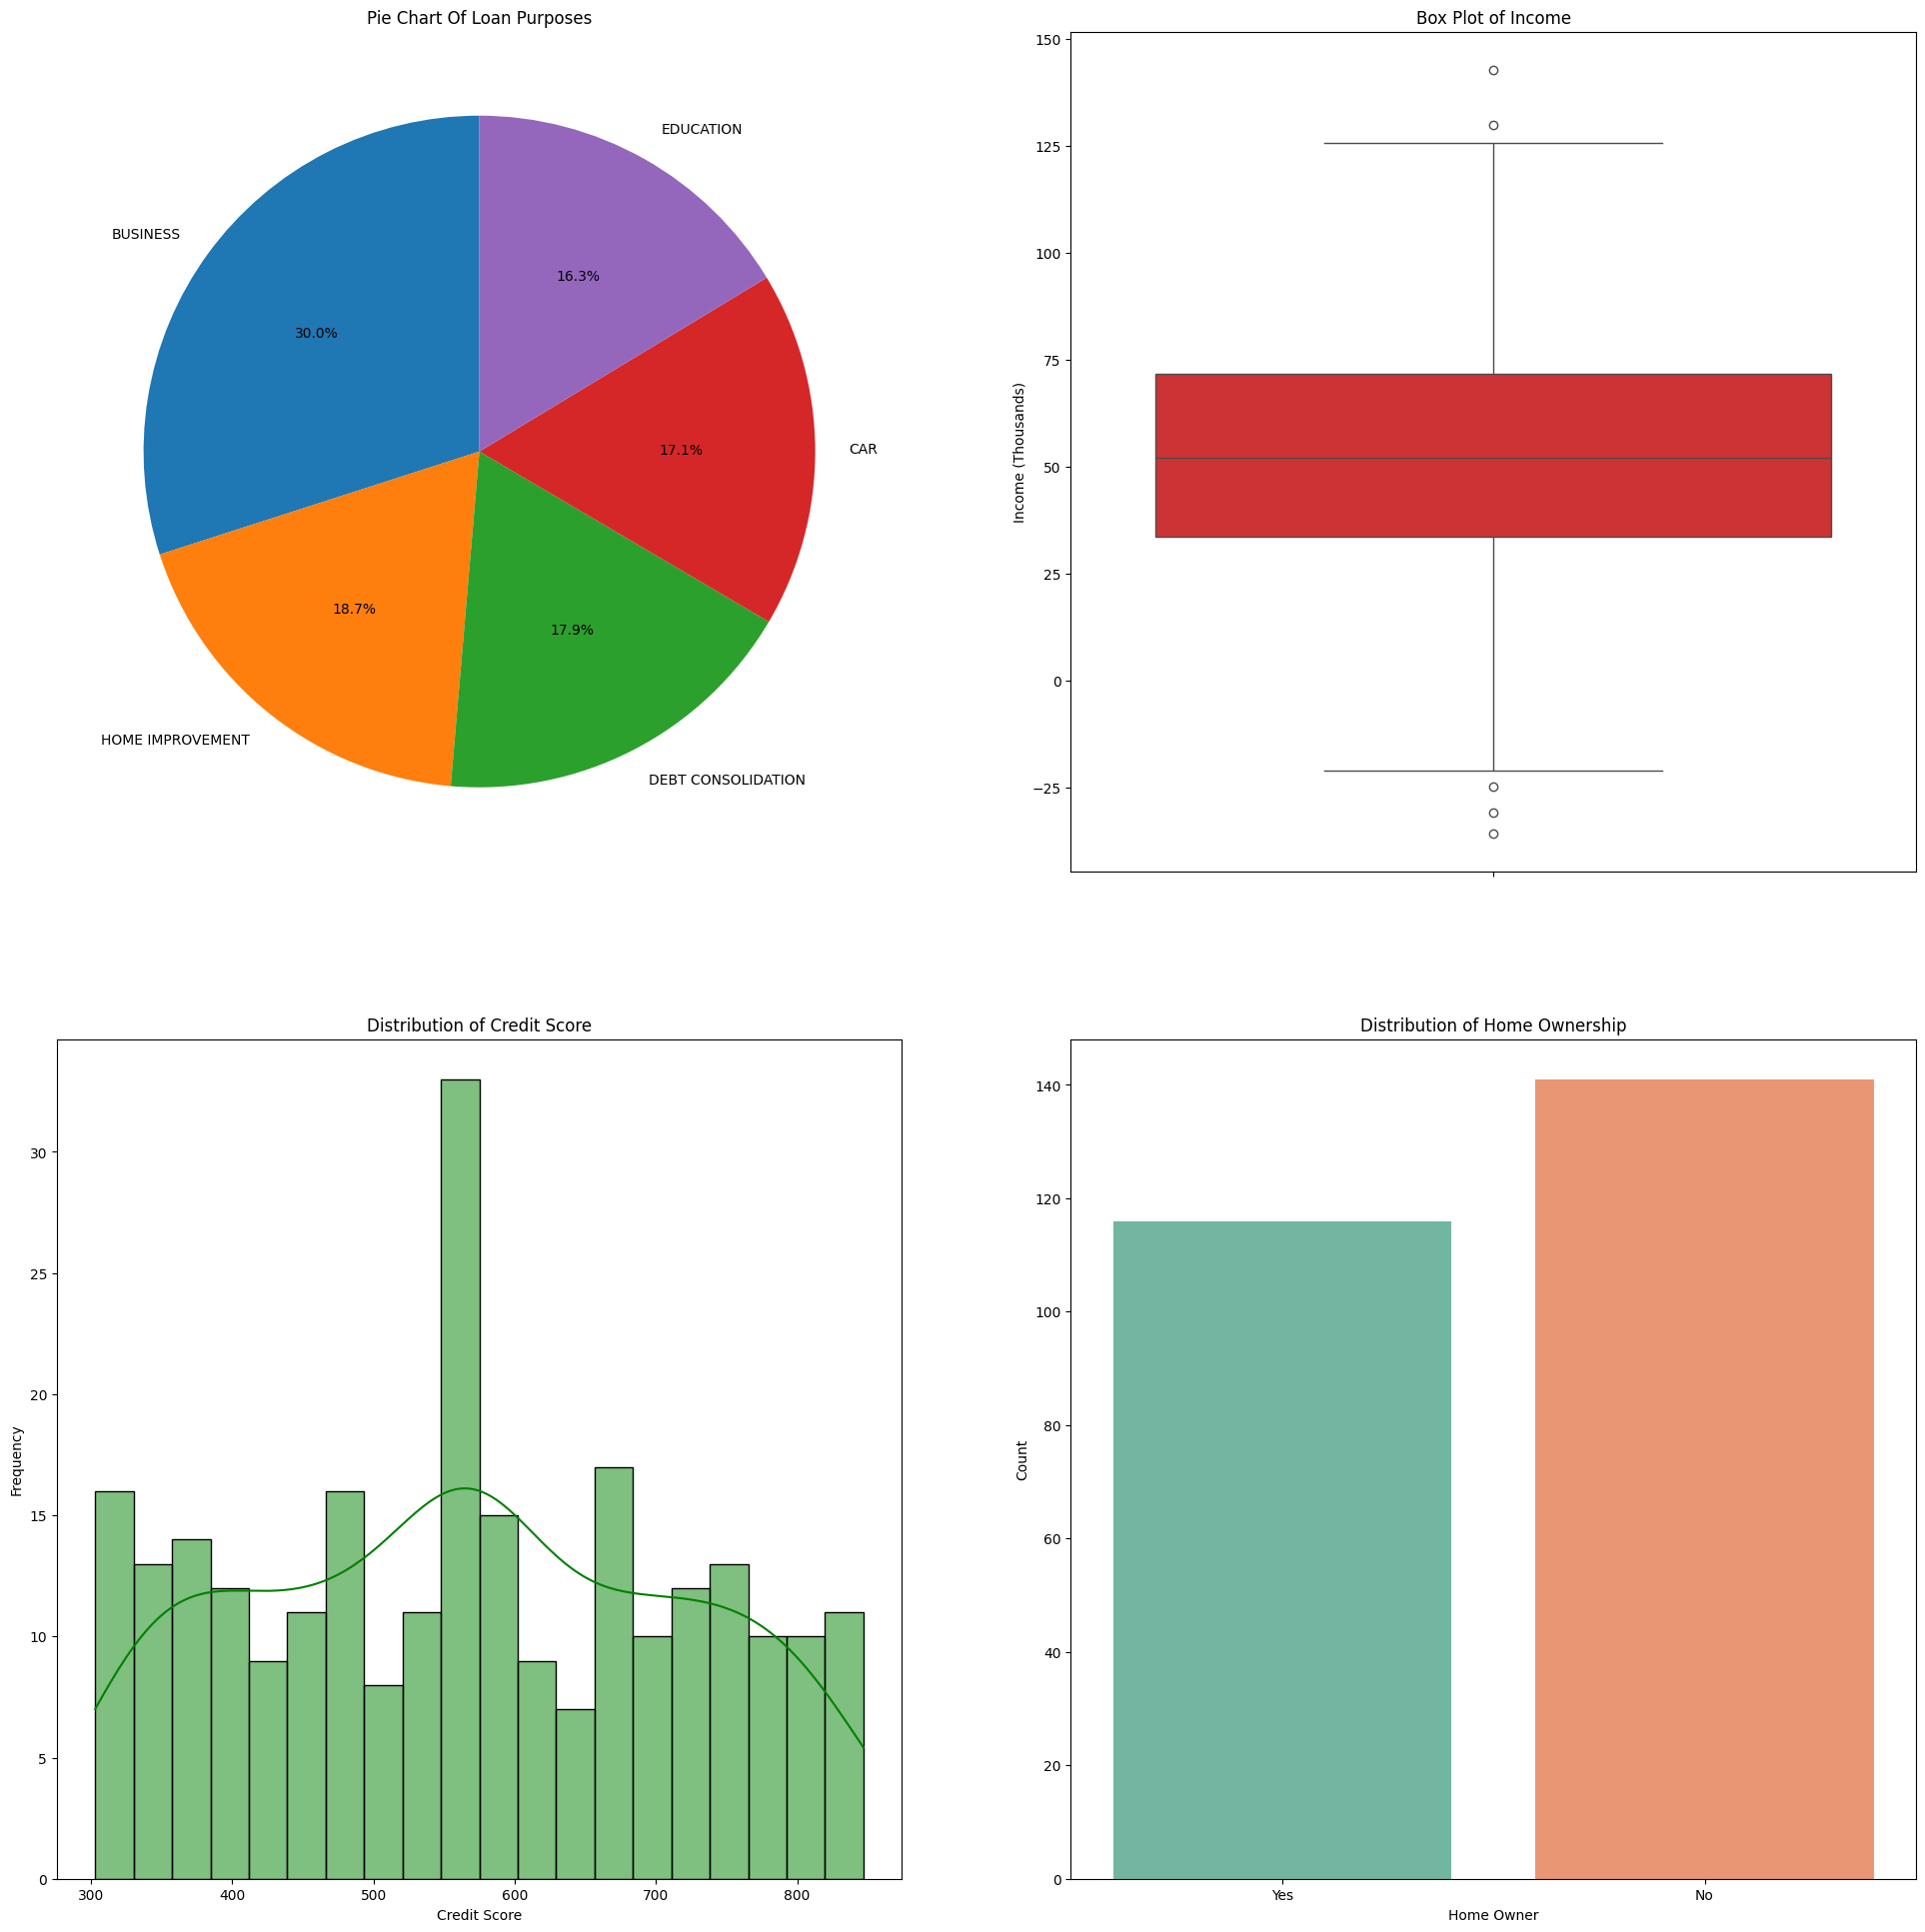

In [108]:
fig,ax = plt.subplots(2,2,figsize=(24,24))
#PIE CHART
loan_counts = df['loan_purpose'].value_counts()
ax[0][0].pie(loan_counts,labels=loan_counts.index,autopct='%1.1f%%',startangle=90)
ax[0][0].set_title('Pie Chart Of Loan Purposes')
#BOXPLOT
sns.boxplot(y=df['income_k'],ax=ax[0][1],palette='Set1')
ax[0][1].set_title('Box Plot of Income')
ax[0][1].set_ylabel('Income (Thousands)')
#HISTOGRAM
sns.histplot(df['credit_score'], ax=ax[1][0], bins=20, kde=True,color='green')
ax[1][0].set_title('Distribution of Credit Score')
ax[1][0].set_xlabel('Credit Score')
ax[1][0].set_ylabel('Frequency')
#cOUNTPLOT
sns.countplot(x=df['home_owner'],ax=ax[1][1],palette='Set2')
ax[1][1].set_title('Distribution of Home Ownership')
ax[1][1].set_xlabel('Home Owner')
ax[1][1].set_ylabel('Count')

Bivariate

In [110]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[
        'Age vs Income',
        'Defaulted vs Credit Score',
        'Loan Purpose vs Loan Amount',
        'Loan Purpose vs Defaulted'
    ],
    specs=[
        [{'type': 'xy'}, {'type': 'xy'}],
        [{'type': 'xy'}, {'type': 'xy'}]
    ]
)

#SCATTER PLOT
for status, color in [(0, 'blue'), (1, 'red')]:
    d = df[df['defaulted'] == status]
    fig.add_trace(
        go.Scatter(
            x=d['age'], y=d['income_k'],
            mode='markers',
            name=f'Defaulted: {status}',
            marker=dict(color=color),
            text=d['credit_score'],
            hovertemplate='Age: %{x}<br>Income: %{y}<br>Credit Score: %{text}<extra></extra>'
        ), row=1, col=1
    )

#BOXPLOT
for status, color in [(0, 'lightgreen'), (1, 'orange')]:
    d = df[df['defaulted'] == status]
    fig.add_trace(
        go.Box(
            y=d['credit_score'],
            name=f'Defaulted: {status}',
            marker_color=color
        ), row=1, col=2
    )

#BARCHART
loan_avg = df.groupby('loan_purpose')['loan_amount_k'].mean().reset_index()

fig.add_trace(
    go.Bar(
        x=loan_avg['loan_purpose'],
        y=loan_avg['loan_amount_k'],
        marker_color='mediumpurple',
        name='Average Loan'
    ), row=2, col=1
)
#GROUPED COUNTPLOT
counts = df.groupby(['loan_purpose', 'defaulted']).size().reset_index(name='count')

for status, color in [(0, 'teal'), (1, 'tomato')]:
    d = counts[counts['defaulted'] == status]
    fig.add_trace(
        go.Bar(
            x=d['loan_purpose'],
            y=d['count'],
            name=f'Defaulted: {status}',
            marker_color=color
        ), row=2, col=2
    )

fig.update_layout(
    height=850,
    width=1100,
    template='plotly_white',
    barmode='group'
)

fig.show()

Multivariate

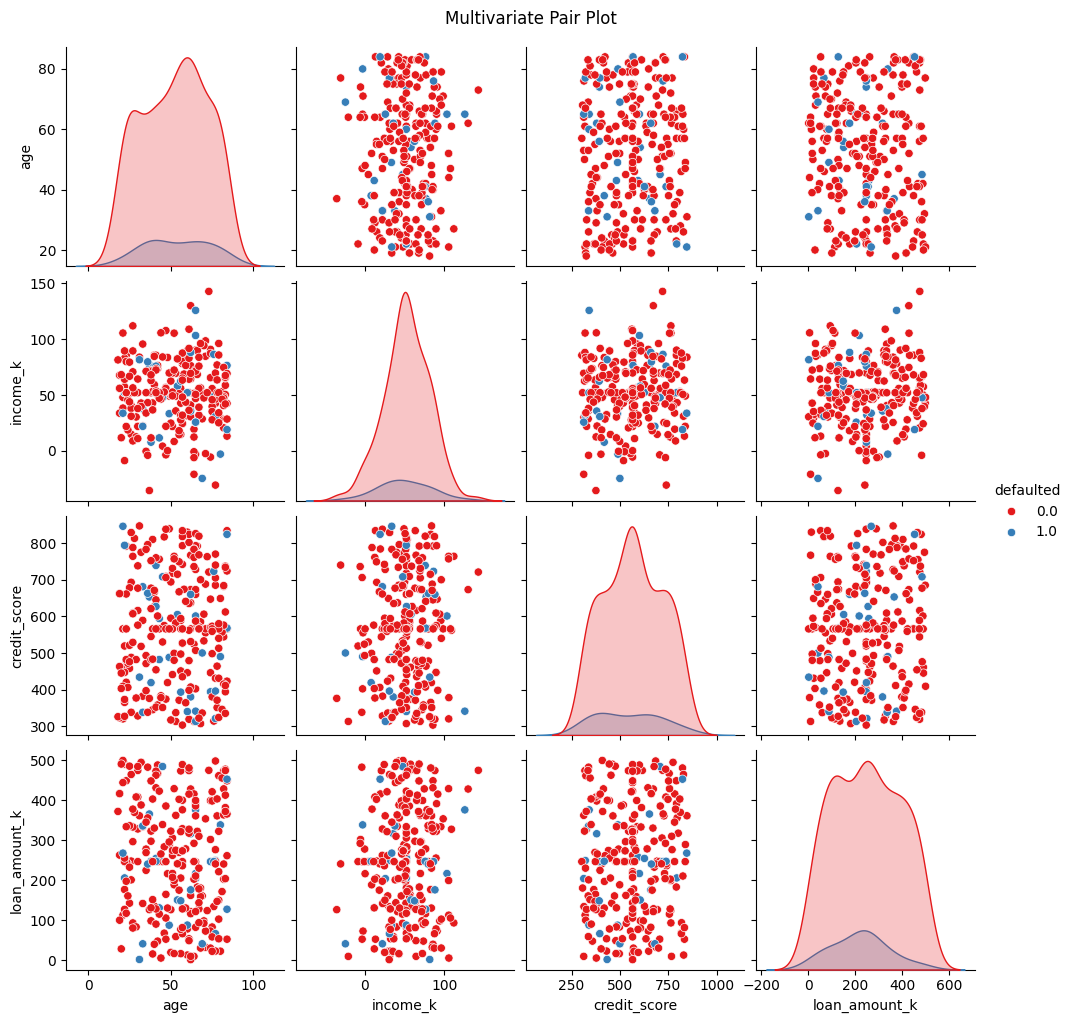

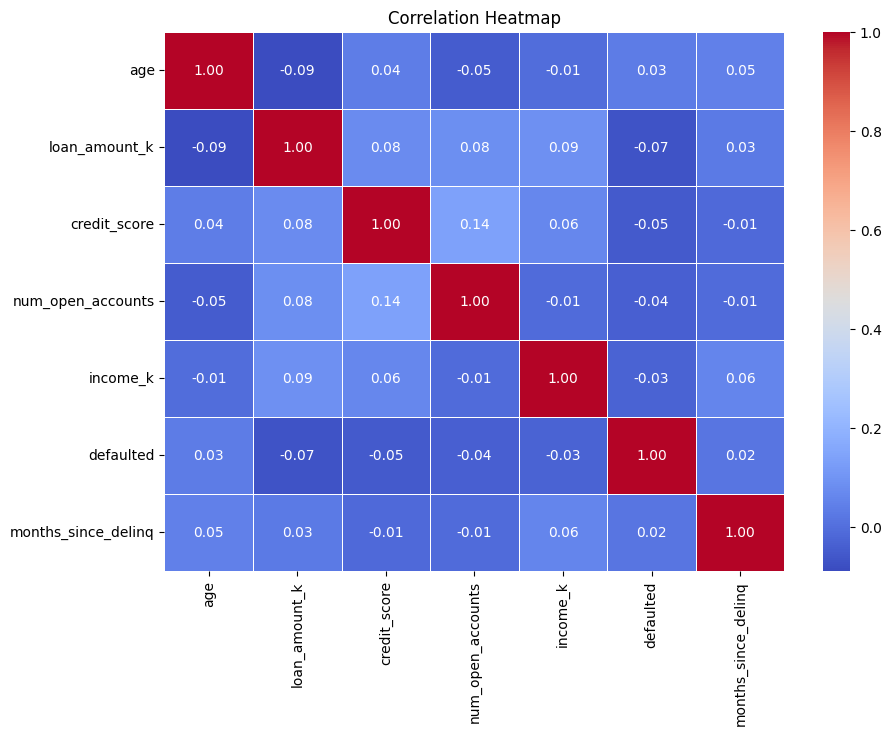

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

#Pair Plot
sns.pairplot(
    df[['age', 'income_k', 'credit_score',
        'loan_amount_k', 'defaulted']],
    hue='defaulted',
    palette='Set1',
    diag_kind='kde'
)

plt.suptitle('Multivariate Pair Plot', y=1.02)
plt.show()
#Correlation Heatmap
plt.figure(figsize=(10, 7))

corr = df.drop(columns=['customer']).select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

**Conclusion**

**Univariate Analysis**


1. Pie Chart – Distribution of Loan Purposes

Conclusion: Business loans account for the highest percentage (30%) of loan applications, followed by Home Improvement (18.7%), Debt Consolidation (17.9%), Car (17.1%), and Education (16.3%). This indicates that business-related loans are the most common purpose among the customers.

2. Box Plot – Distribution of Income

Conclusion: The box plot shows that most customers have an income between approximately 33K and 72K, with a median income of around 52K. A few outliers are present on both the lower and higher sides, indicating variations in customer income.

3. Histogram – Distribution of Credit Score

Conclusion: Credit scores are distributed across a wide range, approximately from 300 to 850. The highest frequency is observed around 550–600, indicating that many customers have credit scores within this range.

4. Count Plot – Home Ownership

Conclusion: The count plot shows that customers without home ownership (No) are slightly higher in number than customers who own a home (Yes). This indicates that a larger proportion of applicants do not own a house.


**Bivariate Analysis**


1. Age vs Income – Scatter Plot

Conclusion: The scatter plot shows the relationship between customers' age and income. The data points are widely scattered, indicating no strong relationship between age and income. Both defaulted and non-defaulted customers are present across different age and income groups.

2. Defaulted vs Credit Score – Box Plot

Conclusion: The box plot compares credit scores of defaulted and non-defaulted customers. The distributions show considerable overlap, suggesting that credit score alone may not be sufficient to determine whether a customer will default on a loan.

3. Loan Purpose vs Loan Amount – Bar Chart

Conclusion: The bar chart compares the average loan amount across different loan purposes. It helps identify how loan requirements vary depending on the purpose of borrowing and highlights differences in average loan amounts among categories.

4. Loan Purpose vs Defaulted – Grouped Bar Chart

Conclusion: The grouped bar chart compares the number of defaulted and non-defaulted customers across different loan purposes. It helps identify which loan categories have higher numbers of defaults and provides insights into repayment patterns.


**Multivariate Analysis**


1. Pair Plot – Relationship Between Multiple Variables

Conclusion: The pair plot displays relationships between Age, Income, Credit Score, Loan Amount, and Default Status. The data points show considerable overlap between defaulted and non-defaulted customers. No strong visual relationship is observed between most numerical variables, indicating that loan default may depend on multiple factors rather than a single variable.

2. Correlation Heatmap – Correlation Between Numerical Variables

Conclusion: The correlation heatmap shows that most numerical variables have very weak correlations with each other. The highest positive correlation is between Credit Score and Number of Open Accounts (0.14), while Age and Loan Amount have a weak negative correlation (-0.09). Defaulted status also has very weak correlations with all numerical variables. This suggests that no single numerical feature has a strong linear relationship with loan default.